In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import FeatureUnion
from sklearn.kernel_approximation import RBFSampler


class ApproximateQLearner:

    def __init__(self, learning=0.01, discount=0.99):

        self.env = gym.make("MountainCar-v0")

        self.learning = learning
        self.discount = discount

        self.n_actions = self.env.action_space.n

        # -------------------------------------------------
        # Build feature transformer
        # -------------------------------------------------

        observation_examples = np.array(
            [self.env.observation_space.sample() for _ in range(10000)]
        )

        self.scaler = StandardScaler()
        self.scaler.fit(observation_examples)

        self.featurizer = FeatureUnion(
            [
                ("rbf1", RBFSampler(gamma=5.0, n_components=100, random_state=1)),
                ("rbf2", RBFSampler(gamma=2.0, n_components=100, random_state=2)),
                ("rbf3", RBFSampler(gamma=1.0, n_components=100, random_state=3)),
                ("rbf4", RBFSampler(gamma=0.5, n_components=100, random_state=4)),
            ]
        )

        self.featurizer.fit(self.scaler.transform(observation_examples))

        self.n_features = 400

        # Small random initialization
        self.weights = np.random.randn(self.n_actions, self.n_features) * 0.01

    # -------------------------------------------------

    def get_features(self, state):

        scaled = self.scaler.transform([state])

        return self.featurizer.transform(scaled)[0]

    # -------------------------------------------------

    def get_q_values(self, features):

        return self.weights @ features

    # -------------------------------------------------

    def get_action(self, features, epsilon):

        if np.random.rand() < epsilon:
            return self.env.action_space.sample()

        return np.argmax(self.get_q_values(features))

    # -------------------------------------------------

    def update(self, features, action, reward, next_features, done):

        current_q = np.dot(self.weights[action], features)

        if done:

            target = reward

        else:

            future_q = np.max(self.get_q_values(next_features))

            target = reward + self.discount * future_q

        td_error = target - current_q

        self.weights[action] += self.learning * td_error * features

    # -------------------------------------------------

    def train(self, episodes=5000, epsilon=0.20, epsilon_decay=0.995, min_epsilon=0.01):

        rewards = []
        average_rewards = []

        for episode in range(episodes):

            state, _ = self.env.reset()

            features = self.get_features(state)

            done = False

            total_reward = 0

            while not done:

                action = self.get_action(features, epsilon)

                next_state, reward, terminated, truncated, _ = self.env.step(action)

                done = terminated or truncated

                next_features = self.get_features(next_state)

                self.update(features, action, reward, next_features, done)

                state = next_state
                features = next_features

                total_reward += reward

            rewards.append(total_reward)

            epsilon = max(min_epsilon, epsilon * epsilon_decay)

            if (episode + 1) % 100 == 0:

                avg = np.mean(rewards[-100:])

                average_rewards.append(avg)

                print(f"Episode {episode+1:4d}" f" | Avg Reward = {avg:.2f}")

        return average_rewards

    def compute_state_values(self, grid_size=50):

        positions = np.linspace(
            self.env.observation_space.low[0],
            self.env.observation_space.high[0],
            grid_size,
        )

        velocities = np.linspace(
            self.env.observation_space.low[1],
            self.env.observation_space.high[1],
            grid_size,
        )

        values = np.zeros((grid_size, grid_size))

        for i, position in enumerate(positions):

            for j, velocity in enumerate(velocities):

                state = np.array([position, velocity])

                features = self.get_features(state)

                q_values = self.get_q_values(features)

                values[j, i] = np.max(q_values)

        return positions, velocities, values

    def plot_state_values(self, grid_size=50):

        positions, velocities, values = self.compute_state_values(grid_size)

        X, Y = np.meshgrid(positions, velocities)

        fig = plt.figure(figsize=(10, 7))

        ax = fig.add_subplot(111, projection="3d")

        surface = ax.plot_surface(X, Y, values, cmap="viridis", edgecolor="none")

        ax.set_title("Approximate Q-Learning State Value Function")

        ax.set_xlabel("Position")
        ax.set_ylabel("Velocity")
        ax.set_zlabel("State Value")

        fig.colorbar(surface, shrink=0.6, aspect=10, label="Value")

        plt.show()

In [ ]:
class ApproximateSARSA(ApproximateQLearner):

    def update(self, features, action, reward, next_features, next_action, done):

        current_q = np.dot(self.weights[action], features)

        if done:

            target = reward

        else:

            next_q = np.dot(self.weights[next_action], next_features)

            target = reward + self.discount * next_q

        td_error = target - current_q

        self.weights[action] += self.learning * td_error * features

    def train(self, episodes=5000, epsilon=0.20, epsilon_decay=0.995, min_epsilon=0.01):

        rewards = []
        average_rewards = []

        for episode in range(episodes):

            state, _ = self.env.reset()

            features = self.get_features(state)

            action = self.get_action(features, epsilon)

            done = False

            total_reward = 0

            while not done:

                next_state, reward, terminated, truncated, _ = self.env.step(action)

                done = terminated or truncated

                next_features = self.get_features(next_state)

                if not done:

                    next_action = self.get_action(next_features, epsilon)

                else:

                    next_action = None

                self.update(features, action, reward, next_features, next_action, done)

                features = next_features

                action = next_action

                total_reward += reward

            rewards.append(total_reward)

            epsilon = max(min_epsilon, epsilon * epsilon_decay)

            if (episode + 1) % 100 == 0:

                avg = np.mean(rewards[-100:])

                average_rewards.append(avg)

                print(f"SARSA Episode {episode+1:4d}" f" | Avg Reward = {avg:.2f}")

        return average_rewards

In [ ]:
class ApproximateExpectedSARSA(ApproximateQLearner):

    def update(self, features, action, reward, next_features, epsilon, done):

        current_q = np.dot(self.weights[action], features)

        if done:

            target = reward

        else:

            q_values = self.get_q_values(next_features)

            probabilities = np.ones(self.n_actions) * (epsilon / self.n_actions)

            best_action = np.argmax(q_values)

            probabilities[best_action] += 1.0 - epsilon

            expected_q = np.sum(probabilities * q_values)

            target = reward + self.discount * expected_q

        td_error = target - current_q

        self.weights[action] += self.learning * td_error * features

    def train(self, episodes=5000, epsilon=0.20, epsilon_decay=0.995, min_epsilon=0.01):

        rewards = []
        average_rewards = []

        for episode in range(episodes):

            state, _ = self.env.reset()

            features = self.get_features(state)

            done = False

            total_reward = 0

            while not done:

                action = self.get_action(features, epsilon)

                next_state, reward, terminated, truncated, _ = self.env.step(action)

                done = terminated or truncated

                next_features = self.get_features(next_state)

                self.update(features, action, reward, next_features, epsilon, done)

                features = next_features

                total_reward += reward

            rewards.append(total_reward)

            epsilon = max(min_epsilon, epsilon * epsilon_decay)

            if (episode + 1) % 100 == 0:

                avg = np.mean(rewards[-100:])

                average_rewards.append(avg)

                print(
                    f"Expected SARSA Episode {episode+1:4d}"
                    f" | Avg Reward = {avg:.2f}"
                )

        return average_rewards

In [ ]:
class ApproximateQLearningAcceleration(ApproximateQLearner):

    def __init__(self, learning=0.01, discount=0.99):

        self.env = gym.make("MountainCar-v0")

        self.learning = learning
        self.discount = discount

        self.n_actions = self.env.action_space.n

        observation_examples = []

        for _ in range(10000):

            state = self.env.observation_space.sample()

            observation_examples.append(self.build_extended_state(state))

        observation_examples = np.array(observation_examples)

        self.scaler = StandardScaler()

        self.scaler.fit(observation_examples)

        self.featurizer = FeatureUnion(
            [
                ("rbf1", RBFSampler(gamma=5.0, n_components=100, random_state=1)),
                ("rbf2", RBFSampler(gamma=2.0, n_components=100, random_state=2)),
                ("rbf3", RBFSampler(gamma=1.0, n_components=100, random_state=3)),
                ("rbf4", RBFSampler(gamma=0.5, n_components=100, random_state=4)),
            ]
        )

        self.featurizer.fit(self.scaler.transform(observation_examples))

        self.n_features = 400

        self.weights = np.random.randn(self.n_actions, self.n_features) * 0.01

    def build_extended_state(self, state):

        position = state[0]

        velocity = state[1]

        acceleration = -0.0025 * np.cos(3 * position)

        return np.array([position, velocity, acceleration])

    def get_features(self, state):

        extended_state = self.build_extended_state(state)

        scaled = self.scaler.transform([extended_state])

        return self.featurizer.transform(scaled)[0]

PART 1 - Approximate Q-Learning
Episode  100 | Avg Reward = -174.17
Episode  200 | Avg Reward = -129.80
Episode  300 | Avg Reward = -120.74
Episode  400 | Avg Reward = -143.61
Episode  500 | Avg Reward = -158.03
Episode  600 | Avg Reward = -139.27
Episode  700 | Avg Reward = -131.75
Episode  800 | Avg Reward = -133.91
Episode  900 | Avg Reward = -129.71
Episode 1000 | Avg Reward = -128.89
Episode 1100 | Avg Reward = -131.00
Episode 1200 | Avg Reward = -134.64
Episode 1300 | Avg Reward = -139.09
Episode 1400 | Avg Reward = -136.63
Episode 1500 | Avg Reward = -144.67
Episode 1600 | Avg Reward = -139.66
Episode 1700 | Avg Reward = -143.67
Episode 1800 | Avg Reward = -145.46
Episode 1900 | Avg Reward = -141.77
Episode 2000 | Avg Reward = -145.55
Episode 2100 | Avg Reward = -144.21
Episode 2200 | Avg Reward = -138.20
Episode 2300 | Avg Reward = -146.14
Episode 2400 | Avg Reward = -140.23
Episode 2500 | Avg Reward = -147.71


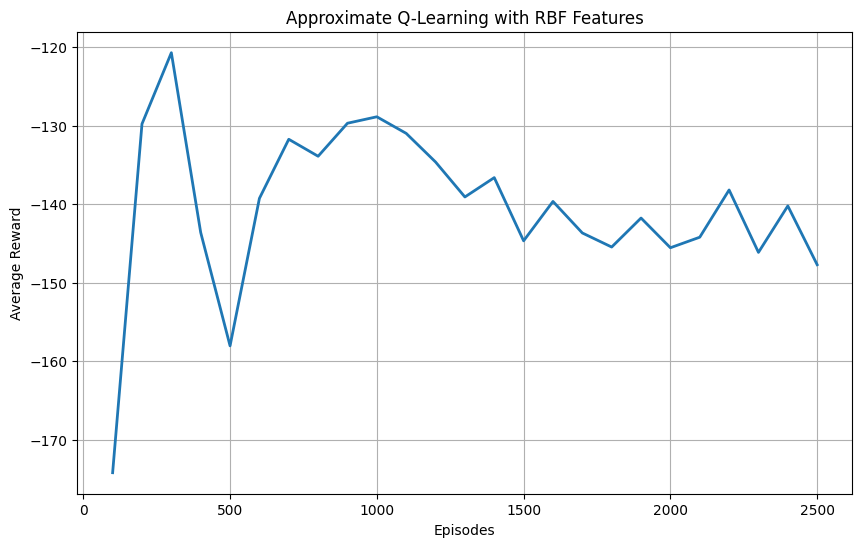

PART 2 - State Value Function


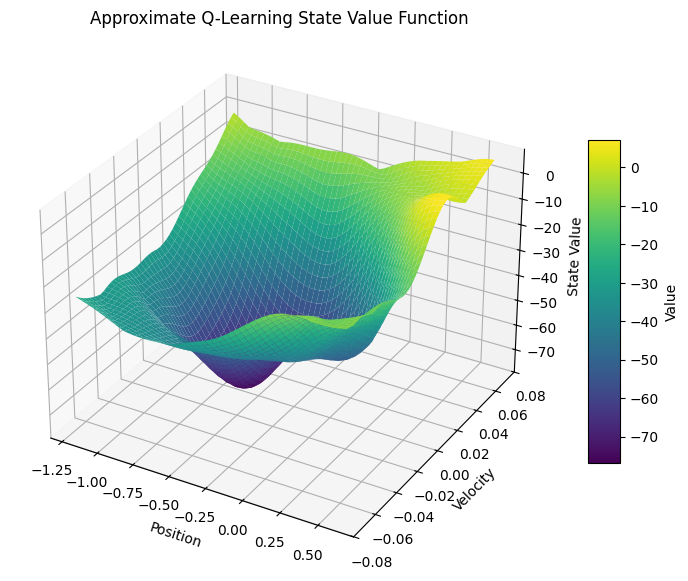

PART 3 - Algorithm Comparison
SARSA Episode  100 | Avg Reward = -183.76
SARSA Episode  200 | Avg Reward = -156.95
SARSA Episode  300 | Avg Reward = -134.16
SARSA Episode  400 | Avg Reward = -139.72
SARSA Episode  500 | Avg Reward = -145.83
SARSA Episode  600 | Avg Reward = -144.73
SARSA Episode  700 | Avg Reward = -146.32
SARSA Episode  800 | Avg Reward = -133.32
SARSA Episode  900 | Avg Reward = -127.96
SARSA Episode 1000 | Avg Reward = -129.94
SARSA Episode 1100 | Avg Reward = -126.31
SARSA Episode 1200 | Avg Reward = -130.23
SARSA Episode 1300 | Avg Reward = -131.24
SARSA Episode 1400 | Avg Reward = -135.78
SARSA Episode 1500 | Avg Reward = -128.68
SARSA Episode 1600 | Avg Reward = -137.34
SARSA Episode 1700 | Avg Reward = -138.69
SARSA Episode 1800 | Avg Reward = -133.18
SARSA Episode 1900 | Avg Reward = -128.72
SARSA Episode 2000 | Avg Reward = -139.29
SARSA Episode 2100 | Avg Reward = -140.36
SARSA Episode 2200 | Avg Reward = -141.82
SARSA Episode 2300 | Avg Reward = -139.32
SARS

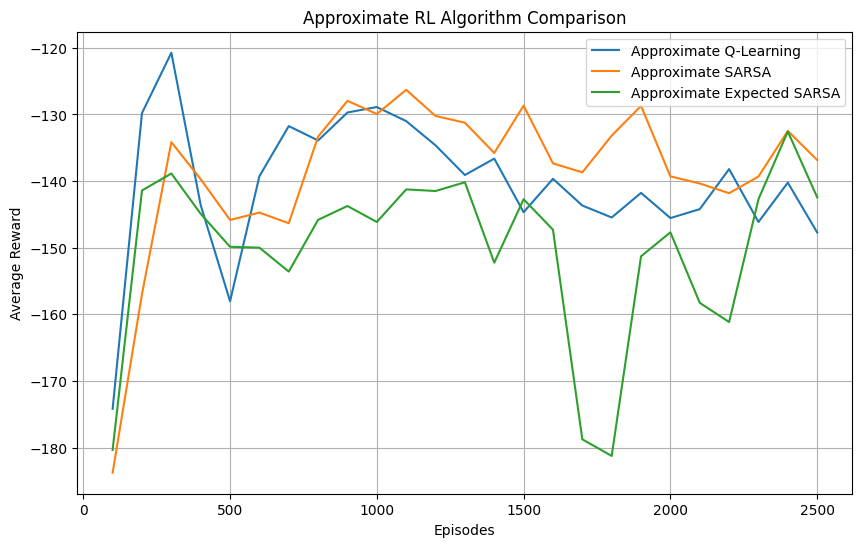

PART 4 - Acceleration Feature
Episode  100 | Avg Reward = -188.01
Episode  200 | Avg Reward = -162.39
Episode  300 | Avg Reward = -146.62
Episode  400 | Avg Reward = -142.73
Episode  500 | Avg Reward = -139.04
Episode  600 | Avg Reward = -135.98
Episode  700 | Avg Reward = -134.16
Episode  800 | Avg Reward = -144.12
Episode  900 | Avg Reward = -142.17
Episode 1000 | Avg Reward = -137.85
Episode 1100 | Avg Reward = -144.51
Episode 1200 | Avg Reward = -141.64
Episode 1300 | Avg Reward = -142.37
Episode 1400 | Avg Reward = -144.98
Episode 1500 | Avg Reward = -143.11
Episode 1600 | Avg Reward = -140.99
Episode 1700 | Avg Reward = -141.31
Episode 1800 | Avg Reward = -141.69
Episode 1900 | Avg Reward = -138.24
Episode 2000 | Avg Reward = -134.36
Episode 2100 | Avg Reward = -130.60
Episode 2200 | Avg Reward = -134.06
Episode 2300 | Avg Reward = -131.33
Episode 2400 | Avg Reward = -131.17
Episode 2500 | Avg Reward = -129.64


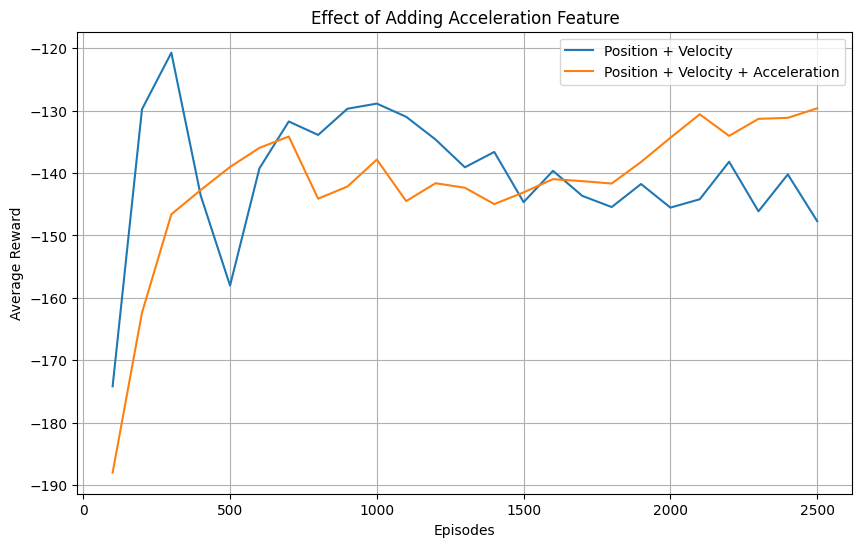

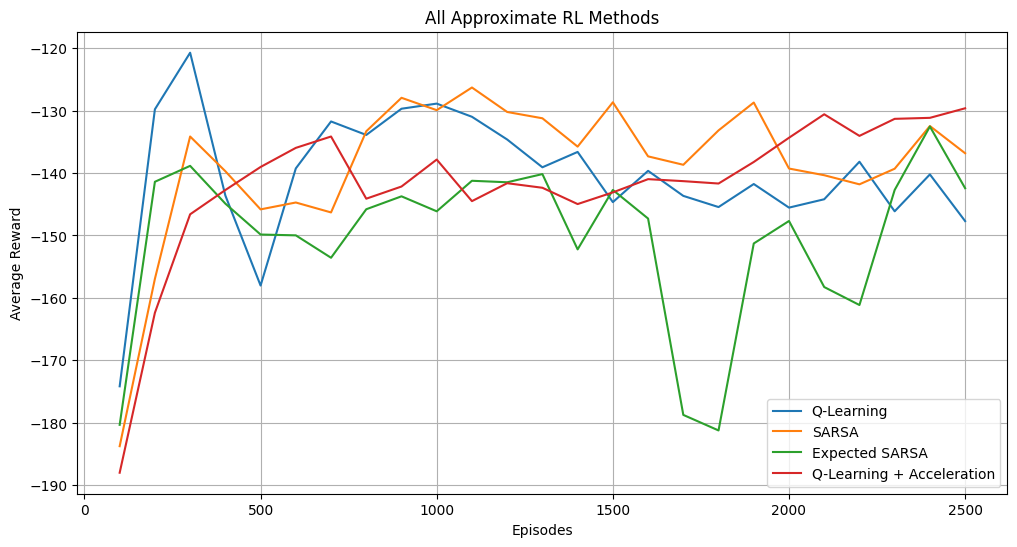

In [ ]:
def main():

    EPISODES = 2500

    #####################################################
    # Part 1
    # Approximate Q-Learning
    #####################################################

    print("=" * 60)
    print("PART 1 - Approximate Q-Learning")
    print("=" * 60)

    q_agent = ApproximateQLearner(learning=0.01, discount=0.99)

    q_rewards = q_agent.train(
        episodes=EPISODES, epsilon=0.20, epsilon_decay=0.995, min_epsilon=0.01
    )

    episodes = np.arange(len(q_rewards)) * 100 + 100

    plt.figure(figsize=(10, 6))

    plt.plot(episodes, q_rewards, linewidth=2)

    plt.xlabel("Episodes")
    plt.ylabel("Average Reward")

    plt.title("Approximate Q-Learning with RBF Features")

    plt.grid(True)

    plt.show()

    #####################################################
    # Part 2
    #####################################################

    print("=" * 60)
    print("PART 2 - State Value Function")
    print("=" * 60)

    q_agent.plot_state_values()

    #####################################################
    # Part 3
    #####################################################

    print("=" * 60)
    print("PART 3 - Algorithm Comparison")
    print("=" * 60)

    sarsa_agent = ApproximateSARSA(learning=0.01, discount=0.99)

    sarsa_rewards = sarsa_agent.train(
        episodes=EPISODES, epsilon=0.20, epsilon_decay=0.995, min_epsilon=0.01
    )

    expected_agent = ApproximateExpectedSARSA(learning=0.01, discount=0.99)

    expected_rewards = expected_agent.train(
        episodes=EPISODES, epsilon=0.20, epsilon_decay=0.995, min_epsilon=0.01
    )

    plt.figure(figsize=(10, 6))

    plt.plot(episodes, q_rewards, label="Approximate Q-Learning")

    plt.plot(episodes, sarsa_rewards, label="Approximate SARSA")

    plt.plot(episodes, expected_rewards, label="Approximate Expected SARSA")

    plt.xlabel("Episodes")
    plt.ylabel("Average Reward")

    plt.title("Approximate RL Algorithm Comparison")

    plt.legend()

    plt.grid(True)

    plt.show()

    #####################################################
    # Part 4
    #####################################################

    print("=" * 60)
    print("PART 4 - Acceleration Feature")
    print("=" * 60)

    accel_agent = ApproximateQLearningAcceleration(learning=0.01, discount=0.99)

    accel_rewards = accel_agent.train(
        episodes=EPISODES, epsilon=0.20, epsilon_decay=0.995, min_epsilon=0.01
    )

    plt.figure(figsize=(10, 6))

    plt.plot(episodes, q_rewards, label="Position + Velocity")

    plt.plot(episodes, accel_rewards, label="Position + Velocity + Acceleration")

    plt.xlabel("Episodes")
    plt.ylabel("Average Reward")

    plt.title("Effect of Adding Acceleration Feature")

    plt.legend()

    plt.grid(True)

    plt.show()

    #####################################################
    # Optional Summary Plot
    #####################################################

    plt.figure(figsize=(12, 6))

    plt.plot(episodes, q_rewards, label="Q-Learning")

    plt.plot(episodes, sarsa_rewards, label="SARSA")

    plt.plot(episodes, expected_rewards, label="Expected SARSA")

    plt.plot(episodes, accel_rewards, label="Q-Learning + Acceleration")

    plt.xlabel("Episodes")
    plt.ylabel("Average Reward")

    plt.title("All Approximate RL Methods")

    plt.legend()

    plt.grid(True)

    plt.show()


if __name__ == "__main__":
    main()